In [ ]:
!pip install -q xlrd statsmodels

import glob, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
sns.set_style("darkgrid")
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

In [ ]:
FILES = sorted(glob.glob("/content/*data*.xls"))
print(FILES)

HDR = re.compile(r"^(?P<var>.+?)\s+Data for station \[(?P<id>[^\]]+)\]\s*-\s*(?P<name>.+?)"
                 r"\s+-?\d+\.\d+\s+-?\d+\.\d+\s+\d+\s*m\s+(?P<year>\d{4})")

def parse_file(path):
    grid = pd.read_excel(path, header=None, dtype=str).values
    rows, cur = [], None
    for r in grid:
        first = "" if pd.isna(r[0]) else str(r[0]).strip()
        m = HDR.match(first)
        if m:
            cur = m.groupdict()
        elif cur and re.fullmatch(r"\d{1,2}(\.0)?", first):
            for month in range(12):
                v = "" if pd.isna(r[month + 1]) else str(r[month + 1]).strip()
                rows.append((cur["name"].strip(), cur["var"].strip(), int(cur["year"]),
                             month + 1, int(float(first)), v))
    return pd.DataFrame(rows, columns=["station", "variable", "year", "month", "day", "raw"])

long = pd.concat([parse_file(f) for f in FILES], ignore_index=True)
print(long.shape, long["station"].nunique(), "stations")

['/content/KwaZulu-Natal 2021-26 data1.xls', '/content/KwaZulu-Natal 2021-26 data2.xls', '/content/KwaZulu-Natal 2021-26 data3.xls', '/content/KwaZulu-Natal 2021-26 data4.xls']
(829188, 6) 34 stations


In [ ]:
NAMES = {"Daily Maximum Temperature (C)": "tmax", "Daily Minimum Temperature (C)": "tmin",
         "Daily Rain (mm)": "rainfall", "Average Wind Speed (m/s)": "wind_speed",
         "Humidity(%)": "humidity"}
long["var"] = long["variable"].map(NAMES)
long = long.dropna(subset=["var"])
long["timestamp"] = pd.to_datetime(long[["year", "month", "day"]], errors="coerce")
long = long.dropna(subset=["timestamp"])
long = long[long["raw"] != "---"]

def to_num(s):
    m = re.match(r"^-?\d+(\.\d+)?", s)
    return float(m.group()) if m else np.nan              # "***" and flags become NaN

long["value"] = long["raw"].map(to_num)
rain = long["var"] == "rainfall"
long.loc[rain & (long["raw"] == ""), "value"] = 0.0       # blank rain cell = no rain

data = (long.pivot_table(index=["station", "timestamp"], columns="var", values="value", aggfunc="first")
            .reset_index())
data = data.drop_duplicates(subset=["station", "timestamp"]).sort_values(["station", "timestamp"])
data["temperature"] = data[["tmax", "tmin"]].mean(axis=1)

FEATURES = ["temperature", "humidity", "rainfall", "wind_speed"]
print("Missing before fill:\n", data[FEATURES].isna().sum())
data[FEATURES] = data.groupby("station")[FEATURES].transform(lambda s: s.ffill(limit=3))   # gaps <= 3 only
data = data.dropna(subset=FEATURES, how="all").reset_index(drop=True)
data["year"] = data["timestamp"].dt.year
print(f"\n{len(data):,} observations | {data['station'].nunique()} stations | "
      f"{data['timestamp'].min().date()} to {data['timestamp'].max().date()}")

Missing before fill:
 var
temperature    4992
humidity       6938
rainfall       1493
wind_speed     3771
dtype: int64

56,457 observations | 34 stations | 2021-01-01 to 2026-03-08


Mean 19.40 | Median 19.80 | SD 4.93 | Min -5.85 | Max 34.65 | Skew -0.421 | Kurt -0.020


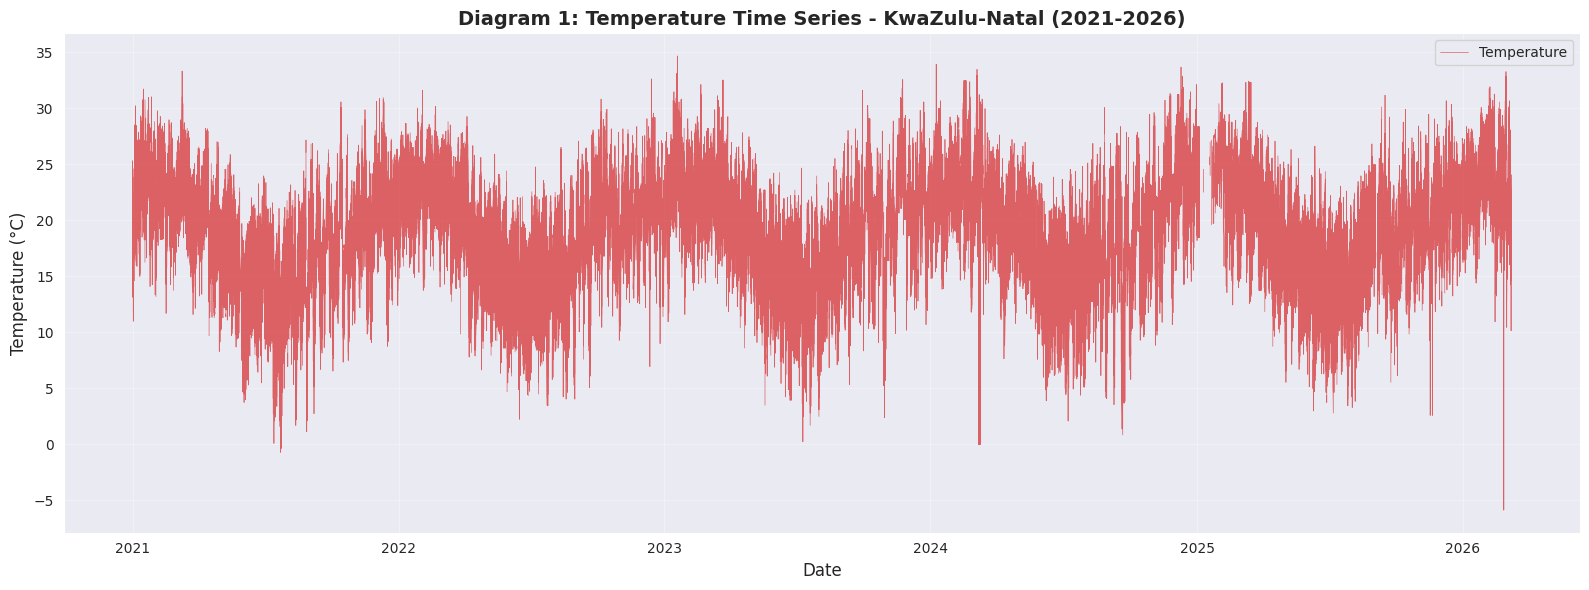

In [ ]:
#diagram 1
t = data["temperature"].dropna()
print(f"Mean {t.mean():.2f} | Median {t.median():.2f} | SD {t.std():.2f} | Min {t.min():.2f} | "
      f"Max {t.max():.2f} | Skew {t.skew():.3f} | Kurt {t.kurtosis():.3f}")

d = data.sort_values("timestamp")
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(d["timestamp"], d["temperature"], color="tab:red", linewidth=0.5, alpha=0.7, label="Temperature")
ax.set_title("Diagram 1: Temperature Time Series - KwaZulu-Natal (2021-2026)", fontsize=14, fontweight="bold")
ax.set_xlabel("Date", fontsize=12); ax.set_ylabel("Temperature (°C)", fontsize=12)
ax.legend(loc="upper right"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("Diagram_1_Temperature_Time_Series.png"); plt.show()


Thresholds -5.60 / +6.00 °C | flagged 2,494 of 52,060 (4.79%)
Increases 495 | decreases 1999
Per year:
 year
2021    475
2022    421
2023    600
2024    539
2025    409
2026     50
Top stations:
 station
CEDARA           140
BABANANGO        138
ORIBI AIRPORT    138
IXOPO            132
KOKSTAD          125
Largest increase:
 var       station  timestamp  temp_change
52703  VAN REENEN 2026-02-27        25.55
Largest decrease:
 var       station  timestamp  temp_change
52702  VAN REENEN 2026-02-26       -25.05


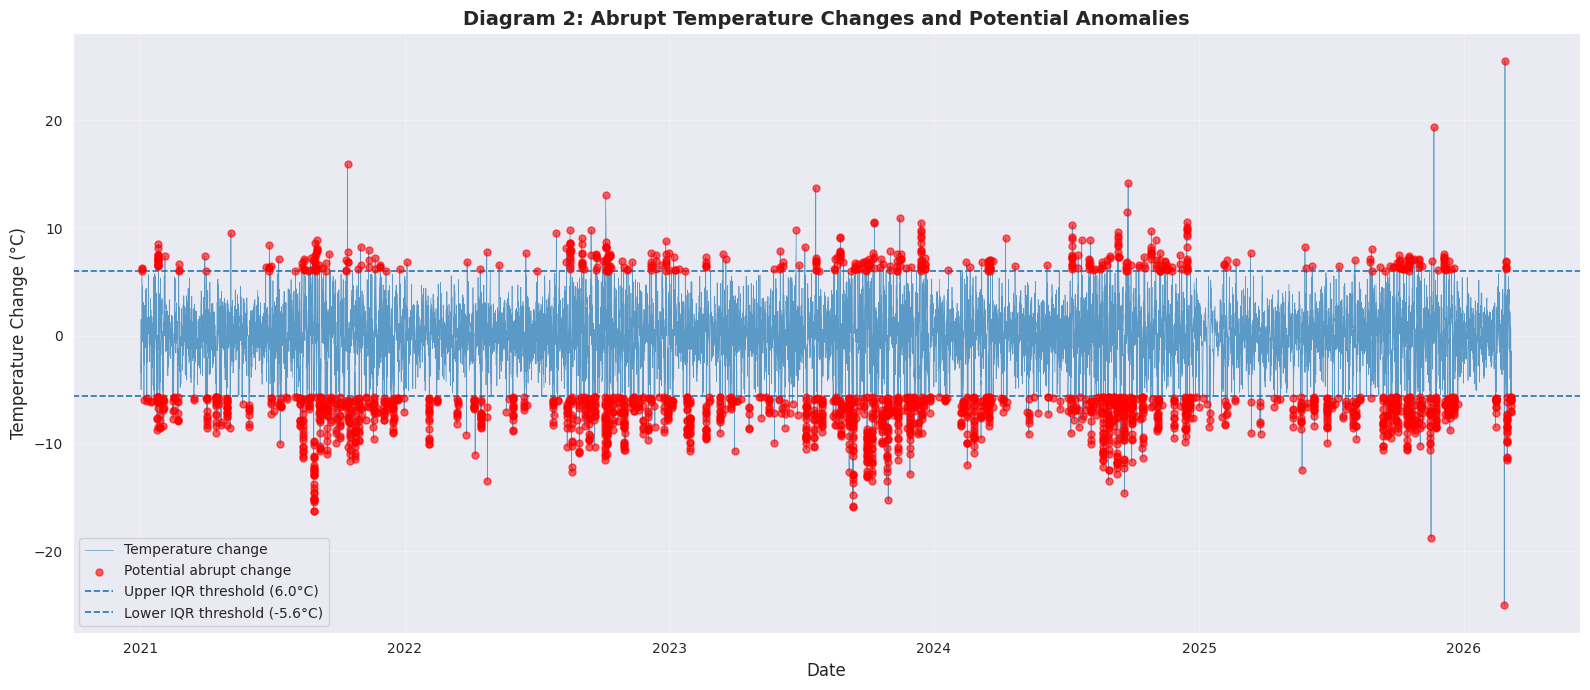

In [ ]:
#diagram 2
data["temp_change"] = data.groupby("station")["temperature"].diff()
ch = data["temp_change"].dropna()
q1, q3 = ch.quantile(0.25), ch.quantile(0.75)
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
data["abrupt"] = (data["temp_change"] < lo) | (data["temp_change"] > hi)
abrupt = data[data["abrupt"]]

print(f"Thresholds {lo:.2f} / +{hi:.2f} °C | flagged {len(abrupt):,} of {len(ch):,} ({len(abrupt)/len(ch):.2%})")
print(f"Increases {(abrupt['temp_change'] > 0).sum()} | decreases {(abrupt['temp_change'] < 0).sum()}")
print("Per year:\n", abrupt.groupby("year").size().to_string())
print("Top stations:\n", abrupt["station"].value_counts().head(5).to_string())
print("Largest increase:\n", data.loc[[data["temp_change"].idxmax()], ["station", "timestamp", "temp_change"]].to_string())
print("Largest decrease:\n", data.loc[[data["temp_change"].idxmin()], ["station", "timestamp", "temp_change"]].to_string())

p = data.dropna(subset=["temp_change"]).sort_values("timestamp")
f = p[p["abrupt"]]
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(p["timestamp"], p["temp_change"], color="tab:blue", linewidth=0.5, alpha=0.7, label="Temperature change")
ax.scatter(f["timestamp"], f["temp_change"], color="red", s=25, alpha=0.6, zorder=3, label="Potential abrupt change")
ax.axhline(hi, color="tab:blue", linestyle="--", linewidth=1.2, label=f"Upper IQR threshold ({hi:.1f}°C)")
ax.axhline(lo, color="tab:blue", linestyle="--", linewidth=1.2, label=f"Lower IQR threshold ({lo:.1f}°C)")
ax.set_title("Diagram 2: Abrupt Temperature Changes and Potential Anomalies", fontsize=14, fontweight="bold")
ax.set_xlabel("Date", fontsize=12); ax.set_ylabel("Temperature Change (°C)", fontsize=12)
ax.legend(loc="lower left"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("Diagram_2_Abrupt_Temperature_Changes.png"); plt.show()


var          temperature  humidity  rainfall  wind_speed
var                                                     
temperature         1.00     -0.05      0.04        0.06
humidity           -0.05      1.00      0.12       -0.24
rainfall            0.04      0.12      1.00        0.03
wind_speed          0.06     -0.24      0.03        1.00
H1a: r = -0.054, p = 1.09e-32, n = 48,142


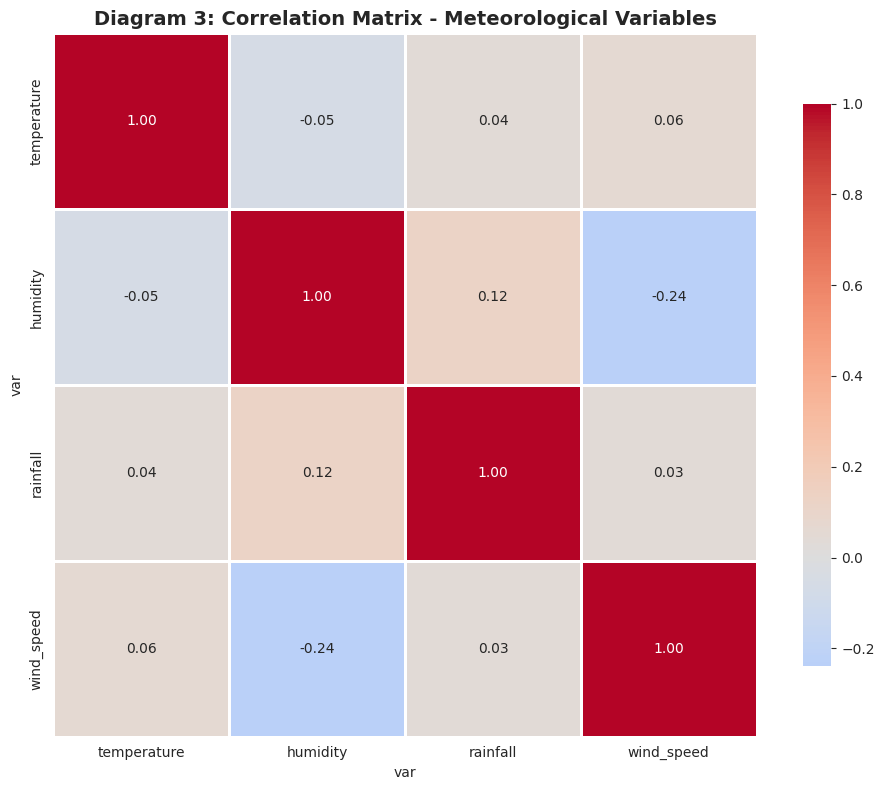

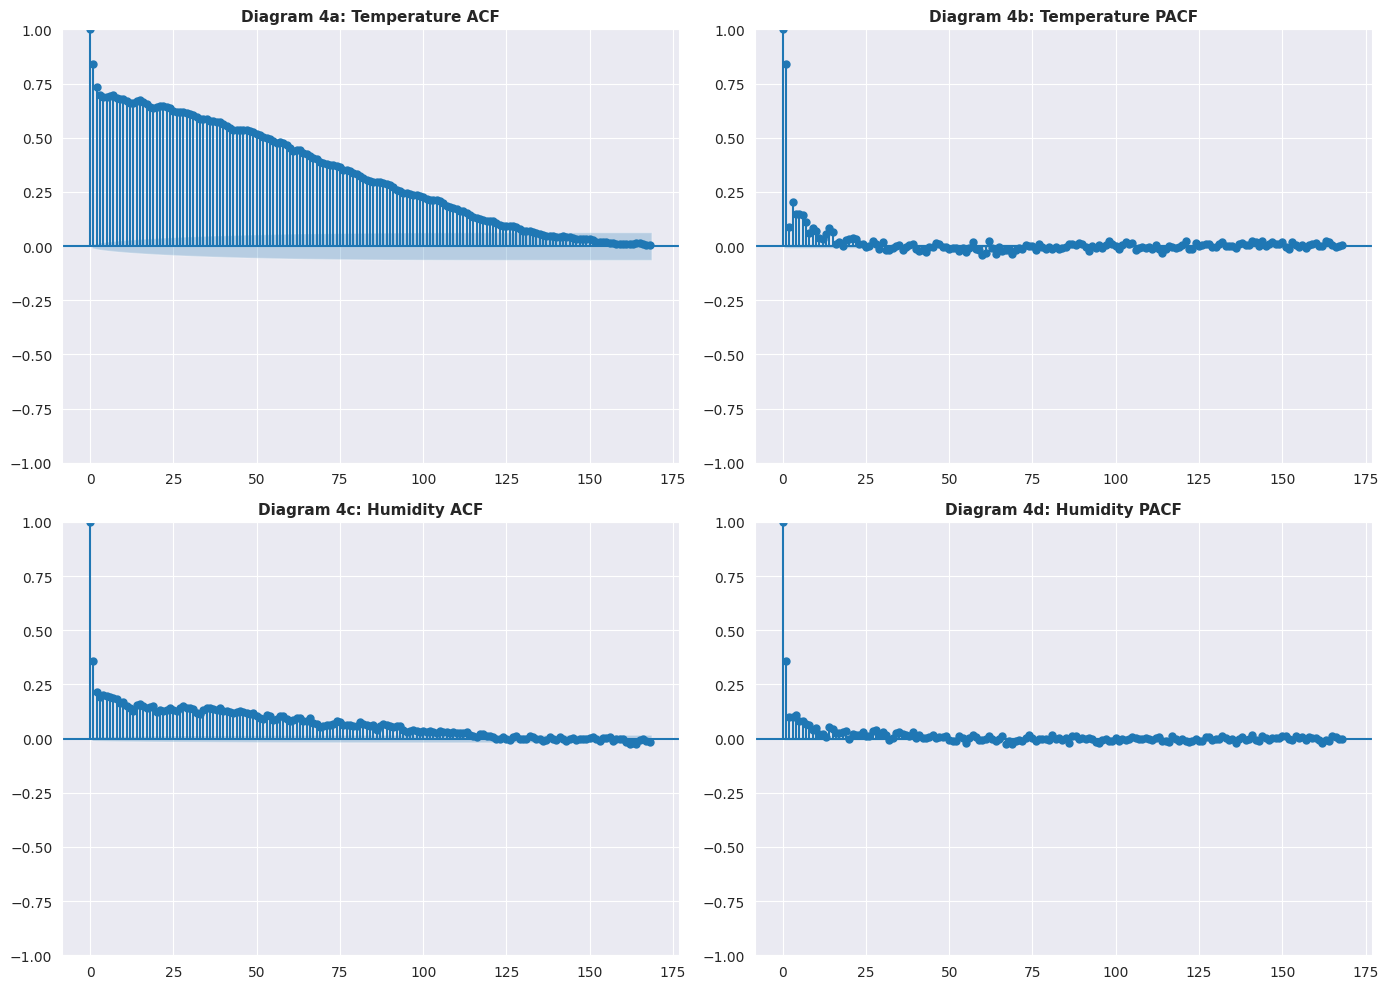

Temperature lag-1 = 0.842
          lb_stat  lb_pvalue
24   5.747965e+05        0.0
168  1.417011e+06        0.0
Humidity lag-1 = 0.356
          lb_stat  lb_pvalue
24   36381.941415        0.0
168  71623.964162        0.0


In [ ]:
#diagram 3
corr = data[FEATURES].corr()
print(corr.round(2))
pair = data[["temperature", "humidity"]].dropna()
r, pv = stats.pearsonr(pair["temperature"], pair["humidity"])
print(f"H1a: r = {r:.3f}, p = {pv:.3g}, n = {len(pair):,}")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=2, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Diagram 3: Correlation Matrix - Meteorological Variables", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig("Diagram_3_Correlation_Matrix.png"); plt.show()

#diagrams 4a to d
ts, hs = data["temperature"].dropna(), data["humidity"].dropna()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_acf(ts, lags=168, ax=axes[0, 0]);  axes[0, 0].set_title("Diagram 4a: Temperature ACF", fontsize=11, fontweight="bold")
plot_pacf(ts, lags=168, ax=axes[0, 1]); axes[0, 1].set_title("Diagram 4b: Temperature PACF", fontsize=11, fontweight="bold")
plot_acf(hs, lags=168, ax=axes[1, 0]);  axes[1, 0].set_title("Diagram 4c: Humidity ACF", fontsize=11, fontweight="bold")
plot_pacf(hs, lags=168, ax=axes[1, 1]); axes[1, 1].set_title("Diagram 4d: Humidity PACF", fontsize=11, fontweight="bold")
for a in axes.ravel():
    a.set_ylim(-1, 1)
plt.tight_layout(); plt.savefig("Diagram_4_ACF_PACF.png"); plt.show()

for name, s in [("Temperature", ts), ("Humidity", hs)]:
    print(name, "lag-1 =", round(s.autocorr(1), 3))
    print(acorr_ljungbox(s, lags=[24, 168], return_df=True))


In [ ]:
model_data = data.dropna(subset=FEATURES).copy()
features = model_data[FEATURES]

iso_forest = IsolationForest(contamination=0.05, random_state=42, n_jobs=-1)
anomaly_labels = iso_forest.fit_predict(features)
anomaly_scores = iso_forest.score_samples(features)

model_data["score"] = anomaly_scores
model_data["anomaly"] = anomaly_labels == -1
anoms = model_data[model_data["anomaly"]]
daily = anoms.groupby("timestamp").size()

print(f"Flagged {len(anoms):,} of {len(model_data):,} ({len(anoms)/len(model_data):.2%})")
print("Per year:\n", anoms.groupby("year").size().to_string())
print(f"Days with anomalies: {len(daily):,} | mean per day {daily.mean():.2f}")
print("Highest days:\n", daily.sort_values(ascending=False).head(5).to_string())
print("Top stations:\n", anoms["station"].value_counts().head(5).to_string())
print(model_data.groupby("anomaly")[FEATURES].mean().round(2))
both = set(zip(abrupt["station"], abrupt["timestamp"])) & set(zip(anoms["station"], anoms["timestamp"]))
print(f"Flagged by both IQR and Isolation Forest: {len(both)}")

Flagged 2,369 of 47,373 (5.00%)
Per year:
 year
2021    468
2022    436
2023    488
2024    483
2025    404
2026     90
Days with anomalies: 754 | mean per day 3.14
Highest days:
 timestamp
2024-09-20    28
2025-11-15    26
2023-10-21    23
2021-01-27    23
2022-12-25    21
Top stations:
 station
KOKSTAD                 159
RICHARDS BAY AIRPORT    155
SHALEBURN               147
ROYAL NATIONAL PARK     140
GIANTS CASTLE AWS       124
var      temperature  humidity  rainfall  wind_speed
anomaly                                             
False          19.37     76.45      1.51        1.45
True           18.36     70.38     25.58        3.35
Flagged by both IQR and Isolation Forest: 302


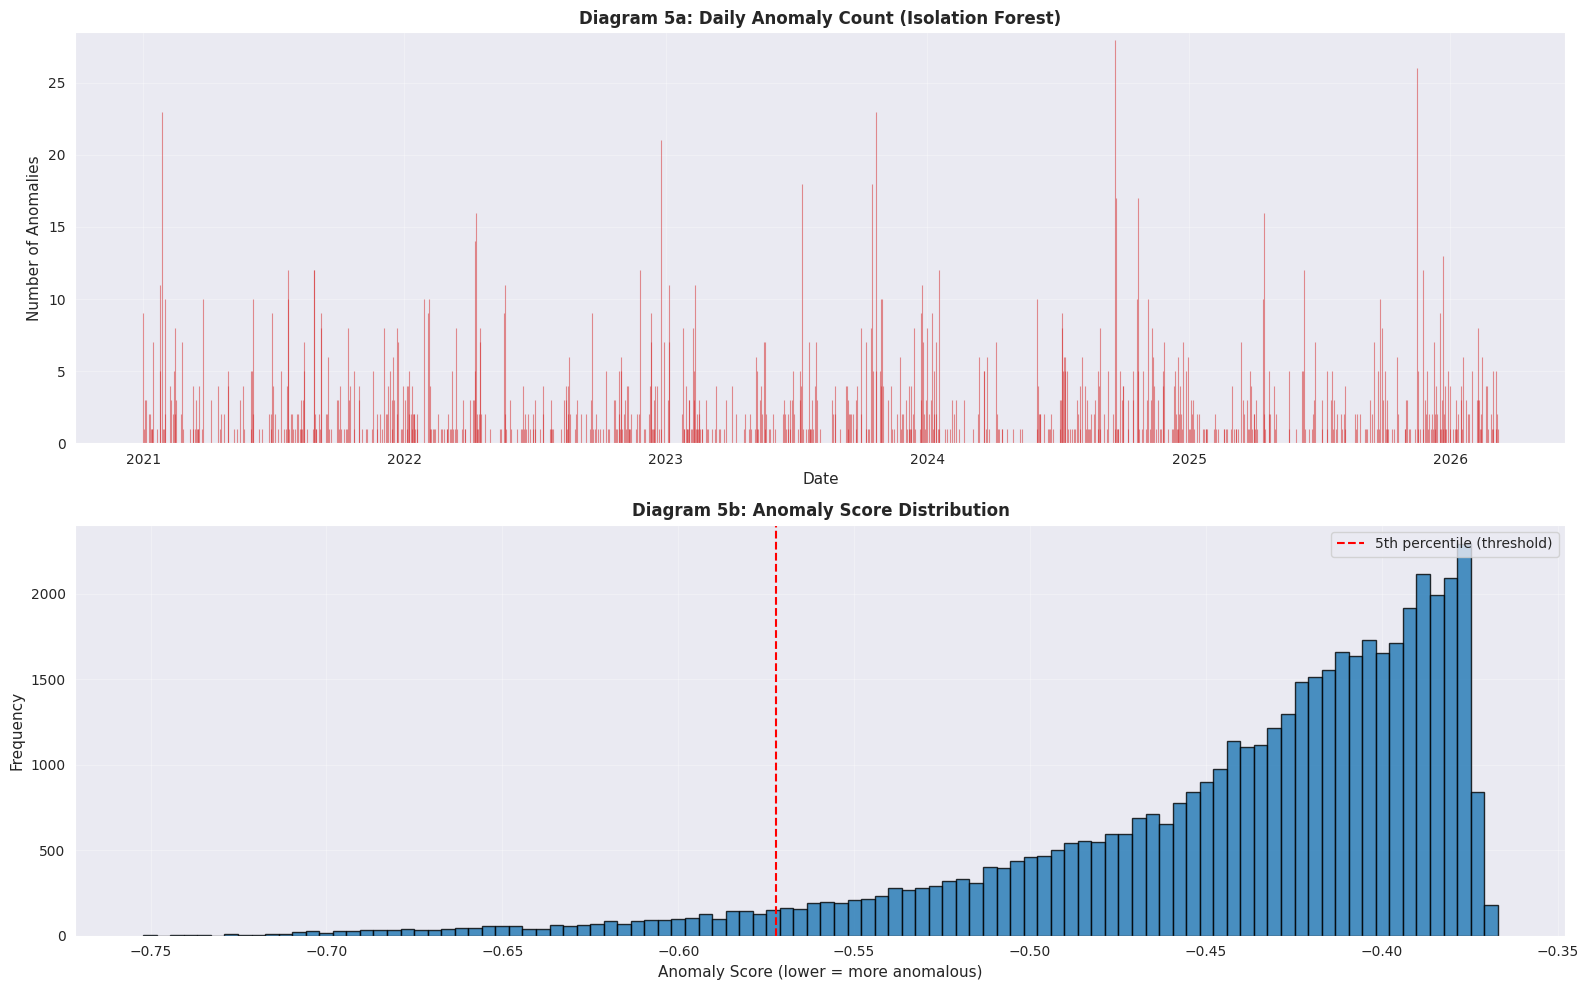

In [ ]:
#diagrams 5a and b

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
days = pd.date_range(model_data["timestamp"].min(), model_data["timestamp"].max(), freq="D")
daily_full = daily.reindex(days, fill_value=0)
axes[0].vlines(daily_full.index, 0, daily_full.values, color="tab:red", alpha=0.5, linewidth=0.8)
axes[0].set_ylim(0, daily_full.max() + 0.5)
axes[0].set_title("Diagram 5a: Daily Anomaly Count (Isolation Forest)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Date", fontsize=11); axes[0].set_ylabel("Number of Anomalies", fontsize=11)
axes[0].xaxis.set_major_locator(mdates.YearLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].grid(True, alpha=0.3)

axes[1].hist(model_data["score"], bins=100, color="tab:blue", edgecolor="black", alpha=0.8)
axes[1].axvline(np.percentile(model_data["score"], 5), color="red", linestyle="--", linewidth=1.5,
                label="5th percentile (threshold)")
axes[1].set_title("Diagram 5b: Anomaly Score Distribution", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Anomaly Score (lower = more anomalous)", fontsize=11); axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].legend(loc="upper right"); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("Diagram_5_Isolation_Forest.png"); plt.show()